# Telco Customer Churn Prediction - Production ML Pipeline

**Goal:** predict customer churn, compare Logistic Regression and XGBoost fairly, explain churn drivers, estimate retention impact, and expose the trained model through FastAPI and Streamlit.

**Dataset:** IBM Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`).

**Workflow:** data validation -> cleaning -> exploratory analysis -> leakage-safe feature engineering -> stratified train/validation/test split -> fold-fitted preprocessing -> cross-validated model comparison -> validation-only threshold selection -> untouched test evaluation -> SHAP explanations -> business impact scenario -> artifact export.

> Run the notebook top to bottom in the `ai` Conda environment. Keep the CSV beside this notebook or update `DATA_PATH`. The notebook writes the deployable model and metadata to `artifacts/`.


## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve, brier_score_loss
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)


pandas: 2.3.3
scikit-learn: 1.7.2
xgboost: 3.2.0


## 2. Load and validate data

In [2]:
if not DATA_PATH.exists():
    # Convenient fallback for this uploaded-file environment; change DATA_PATH for your own machine.
    fallback = Path("/mnt/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
    if fallback.exists():
        DATA_PATH = fallback
    else:
        raise FileNotFoundError(
            f"Dataset not found at {DATA_PATH.resolve()}. Put the CSV beside this notebook or update DATA_PATH."
        )

raw_df = pd.read_csv(DATA_PATH)
required_columns = {
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
    "MonthlyCharges", "TotalCharges", "Churn"
}
missing_columns = required_columns - set(raw_df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print(f"Rows: {len(raw_df):,} | Columns: {raw_df.shape[1]}")
display(raw_df.head())
display(pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing": raw_df.isna().sum(),
    "unique_values": raw_df.nunique(dropna=False)
}))
print("Duplicate rows:", raw_df.duplicated().sum())
print("Duplicate customer IDs:", raw_df["customerID"].duplicated().sum())


Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,dtype,missing,unique_values
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Duplicate rows: 0
Duplicate customer IDs: 0


## 3. Clean target and numeric fields

In [3]:
df = raw_df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
# In this dataset, blank TotalCharges values correspond to customers with zero tenure.
zero_tenure = df["tenure"].eq(0)
df.loc[zero_tenure & df["TotalCharges"].isna(), "TotalCharges"] = 0.0

# Explicit checks prevent silent target corruption.
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
if df["Churn"].isna().any():
    raise ValueError("Unexpected or missing target values found in Churn.")
if df["customerID"].duplicated().any():
    print("Warning: duplicate customer IDs found; inspect before interpreting results.")

print("Target counts:")
display(df["Churn"].value_counts().rename(index={0: "No churn", 1: "Churn"}).to_frame("customers"))
print(f"Overall churn rate: {df['Churn'].mean():.2%}")
print("TotalCharges missing after zero-tenure handling:", int(df["TotalCharges"].isna().sum()))
print("Zero-tenure customers:", int(zero_tenure.sum()))


Target counts:


,customers
Churn,
No churn,5174
Churn,1869


Overall churn rate: 26.54%
TotalCharges missing after zero-tenure handling: 0
Zero-tenure customers: 11


## 4. Exploratory data analysis

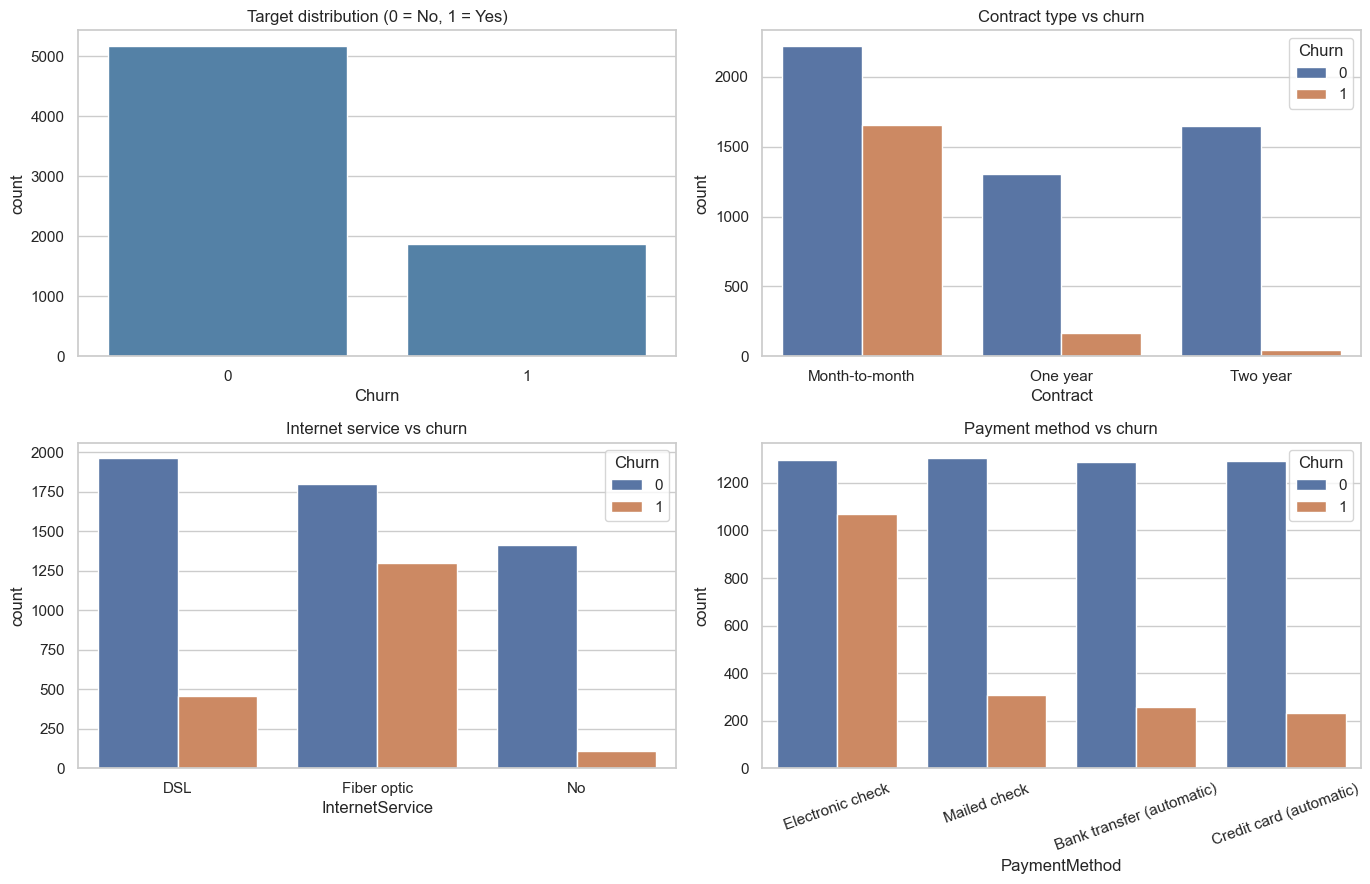

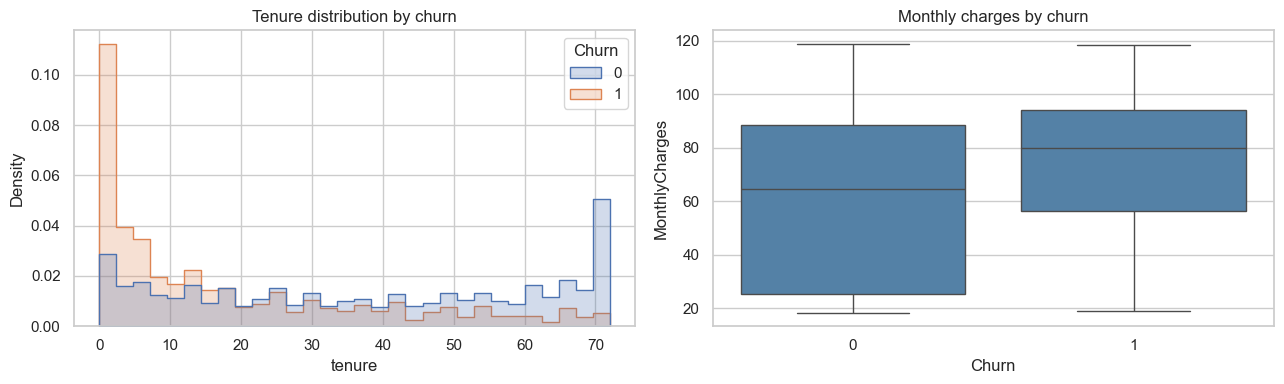

Observed churn rate by contract:


,churn_rate_percent
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(data=df, x="Churn", color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Target distribution (0 = No, 1 = Yes)")
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Contract type vs churn")
sns.countplot(data=df, x="InternetService", hue="Churn", ax=axes[1, 0])
axes[1, 0].set_title("Internet service vs churn")
sns.countplot(data=df, x="PaymentMethod", hue="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Payment method vs churn")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Tenure distribution by churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", color="steelblue", ax=axes[1])
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.show()

churn_by_contract = pd.crosstab(df["Contract"], df["Churn"], normalize="index")[1].sort_values(ascending=False)
print("Observed churn rate by contract:")
display((100 * churn_by_contract).rename("churn_rate_percent").round(2).to_frame())


## 5. Feature engineering

Create two transparent customer-level features: number of subscribed add-on services and average historical charges per month of tenure. The customer ID is excluded because it is an identifier, not a meaningful predictive feature. The cohort feature is omitted to avoid redundant binning of tenure; tenure remains available as a numeric variable.

In [5]:
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
model_df = df.drop(columns=["customerID"]).copy()
model_df["TotalServices"] = model_df[service_cols].eq("Yes").sum(axis=1)
model_df["AvgMonthlySpend"] = np.where(
    model_df["tenure"].gt(0),
    model_df["TotalCharges"] / model_df["tenure"].replace(0, np.nan),
    model_df["MonthlyCharges"]
)
# Keep engineered values finite; any remaining missing values are handled inside the pipeline.
model_df["AvgMonthlySpend"] = model_df["AvgMonthlySpend"].replace([np.inf, -np.inf], np.nan)
display(model_df[["tenure", "TotalCharges", "MonthlyCharges", "TotalServices", "AvgMonthlySpend", "Churn"]].head())


,tenure,TotalCharges,MonthlyCharges,TotalServices,AvgMonthlySpend,Churn
0,1,29.85,29.85,1,29.850000,0
1,34,1889.50,56.95,2,55.573529,0
2,2,108.15,53.85,2,54.075000,1
3,45,1840.75,42.30,3,40.905556,0
4,2,151.65,70.70,0,75.825000,1


## 6. Split into train, validation, and test sets

The data is split into 70% training, 15% validation, and 15% test partitions with stratification and a fixed random seed. The test set remains untouched until final evaluation. The validation set is used only for operating-threshold selection, preventing test labels from influencing the decision rule.


In [6]:
X = model_df.drop(columns="Churn")
y = model_df["Churn"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train: {X_train.shape} | Validation: {X_valid.shape} | Test: {X_test.shape}")
print("Churn rates:", {
    "train": round(float(y_train.mean()), 4),
    "validation": round(float(y_valid.mean()), 4),
    "test": round(float(y_test.mean()), 4)
})


Train: (4930, 21) | Validation: (1056, 21) | Test: (1057, 21)
Churn rates: {'train': 0.2653, 'validation': 0.2652, 'test': 0.2658}


## 7. Preprocessing and model definitions

In [7]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Compare an interpretable linear baseline with a nonlinear boosted-tree model.
# class_weight / scale_pos_weight are estimated from training labels only.
positive_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=350,
        learning_rate=0.04,
        max_depth=4,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        scale_pos_weight=positive_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}
print("Numeric features:", numeric_features)
print("Categorical features:", len(categorical_features))
print(f"Training-only scale_pos_weight: {positive_weight:.3f}")


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'AvgMonthlySpend']
Categorical features: 15
Training-only scale_pos_weight: 2.769


## 8. Cross-validation and model comparison

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "average_precision": "average_precision", "f1": "f1"}

cv_rows = []
fitted_models = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False, error_score="raise"
    )
    cv_rows.append({
        "model": name,
        "CV ROC-AUC mean": scores["test_roc_auc"].mean(),
        "CV ROC-AUC std": scores["test_roc_auc"].std(),
        "CV PR-AUC mean": scores["test_average_precision"].mean(),
        "CV F1 mean": scores["test_f1"].mean()
    })
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC mean", ascending=False)
display(cv_results.round(4))


,model,CV ROC-AUC mean,CV ROC-AUC std,CV PR-AUC mean,CV F1 mean
0,Logistic Regression,0.8439,0.0121,0.6580,0.6226
1,XGBoost,0.8423,0.0127,0.6643,0.6301


## 9. Select model and tune decision threshold on validation data

The model is selected using cross-validation ROC-AUC on the training set. The decision threshold is then selected using validation F1. Threshold choice depends on business costs; F1 is a baseline objective, not a universal optimum.

Selected model: Logistic Regression
Validation ROC-AUC: 0.8449
Validation PR-AUC: 0.6299
F1-selected validation threshold: 0.5410


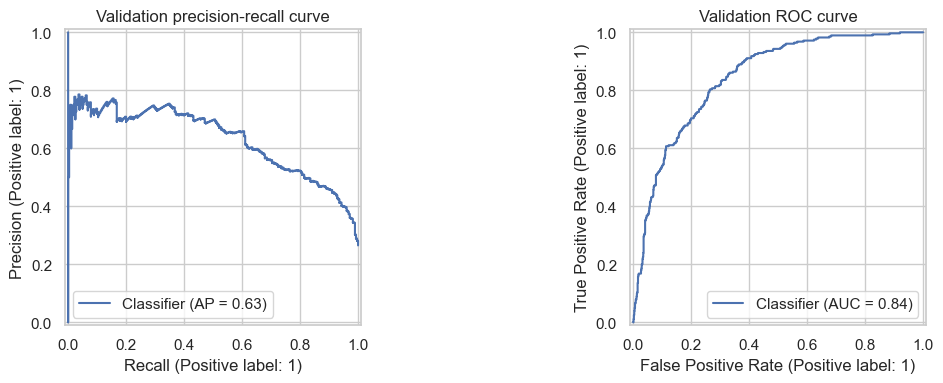

In [9]:
best_model_name = cv_results.iloc[0]["model"]
best_model = fitted_models[best_model_name]
valid_proba = best_model.predict_proba(X_valid)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_valid, valid_proba)
# precision/recall have one more element than thresholds; threshold candidates use all but last.
f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
if len(thresholds) == 0:
    best_threshold = 0.5
else:
    best_threshold = float(thresholds[int(np.nanargmax(f1_values))])

print("Selected model:", best_model_name)
print(f"Validation ROC-AUC: {roc_auc_score(y_valid, valid_proba):.4f}")
print(f"Validation PR-AUC: {average_precision_score(y_valid, valid_proba):.4f}")
print(f"F1-selected validation threshold: {best_threshold:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
PrecisionRecallDisplay.from_predictions(y_valid, valid_proba, ax=axes[0])
axes[0].set_title("Validation precision-recall curve")
RocCurveDisplay.from_predictions(y_valid, valid_proba, ax=axes[1])
axes[1].set_title("Validation ROC curve")
plt.tight_layout()
plt.show()


## 10. Final evaluation on the untouched test set

,setting,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
0,Default threshold,0.500,0.7474,0.5165,0.7794,0.6213,0.8447,0.6577,0.1629
1,Validation-tuned threshold,0.541,0.7625,0.5387,0.7438,0.6248,0.8447,0.6577,0.1629


Classification report (validation-tuned threshold):
              precision    recall  f1-score   support

    No churn     0.8924    0.7693    0.8263       776
       Churn     0.5387    0.7438    0.6248       281

    accuracy                         0.7625      1057
   macro avg     0.7155    0.7566    0.7256      1057
weighted avg     0.7983    0.7625    0.7727      1057



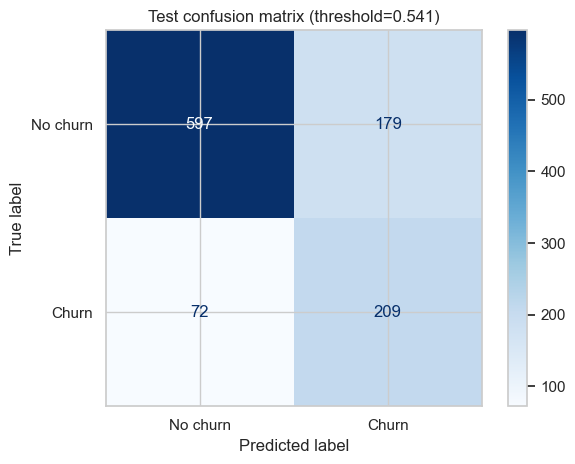

In [10]:
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred_05 = (test_proba >= 0.5).astype(int)
test_pred_tuned = (test_proba >= best_threshold).astype(int)

def metric_row(y_true, y_prob, threshold, label):
    pred = (y_prob >= threshold).astype(int)
    return {
        "setting": label,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "brier_score": brier_score_loss(y_true, y_prob)
    }

test_metrics = pd.DataFrame([
    metric_row(y_test, test_proba, 0.5, "Default threshold"),
    metric_row(y_test, test_proba, best_threshold, "Validation-tuned threshold")
])
display(test_metrics.round(4))
print("Classification report (validation-tuned threshold):")
print(classification_report(y_test, test_pred_tuned, target_names=["No churn", "Churn"], digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred_tuned, display_labels=["No churn", "Churn"], cmap="Blues"
)
plt.title(f"Test confusion matrix (threshold={best_threshold:.3f})")
plt.tight_layout()
plt.show()


## 11. Model explainability with SHAP

SHAP is calculated on transformed held-out test rows for whichever model is selected by cross-validation. Logistic Regression uses `shap.LinearExplainer`; XGBoost uses `shap.TreeExplainer`. One-hot encoded contributions are aggregated back to business-level features so the resulting drivers can support retention actions. SHAP describes model behavior, not causality.


In [11]:
if best_model_name == "XGBoost":
    import shap

    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_classifier = best_model.named_steps["classifier"]
    X_test_transformed = fitted_preprocessor.transform(X_test)
    feature_names = fitted_preprocessor.get_feature_names_out()

    # Explain a bounded sample for faster runtime and lower memory usage.
    sample_size = min(300, X_test_transformed.shape[0])
    rng = np.random.default_rng(RANDOM_STATE)
    sample_idx = rng.choice(X_test_transformed.shape[0], size=sample_size, replace=False)
    X_shap = X_test_transformed[sample_idx]

    explainer = shap.TreeExplainer(fitted_classifier)
    shap_values = explainer.shap_values(X_shap)

    shap.summary_plot(
        shap_values, X_shap, feature_names=feature_names,
        max_display=15, show=False
    )
    plt.title("SHAP summary - top feature contributions")
    plt.tight_layout()
    plt.show()
else:
    print("SHAP tree explanation skipped because the selected model is not XGBoost.")


SHAP tree explanation skipped because the selected model is not XGBoost.


## 12. Save the model, threshold, and metadata

The serialized scikit-learn pipeline includes preprocessing and the selected classifier. The metadata records the selected model, validation-tuned threshold, feature groups, test metrics, and package versions. Raw inference records are transformed with the same deterministic feature-engineering helper before prediction.


In [12]:
artifact_path = ARTIFACT_DIR / "telco_churn_pipeline.joblib"
metadata_path = ARTIFACT_DIR / "telco_churn_metadata.json"

joblib.dump(best_model, artifact_path)
metadata = {
    "selected_model": best_model_name,
    "decision_threshold": best_threshold,
    "random_state": RANDOM_STATE,
    "dataset_rows": int(len(df)),
    "dataset_features_before_engineering": int(raw_df.shape[1] - 1),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "test_metrics_tuned_threshold": test_metrics.iloc[1].to_dict(),
    "versions": {
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__
    }
}
metadata_path.write_text(json.dumps(metadata, indent=2, default=float))
print("Saved model:", artifact_path.resolve())
print("Saved metadata:", metadata_path.resolve())


Saved model: C:\Amulya\Projects\Telco-Customer-Churn\artifacts\telco_churn_pipeline.joblib
Saved metadata: C:\Amulya\Projects\Telco-Customer-Churn\artifacts\telco_churn_metadata.json


## 13. Reusable prediction function and smoke test

In [13]:
def prepare_customer_records(raw_records: pd.DataFrame) -> pd.DataFrame:
    """Convert raw customer records into the features expected by the saved pipeline."""
    records = raw_records.copy()
    records = records.drop(columns=["customerID", "Churn"], errors="ignore")

    if "TotalCharges" in records:
        records["TotalCharges"] = pd.to_numeric(
            records["TotalCharges"].astype(str).str.strip(), errors="coerce"
        )
        if "tenure" in records:
            zero_tenure_mask = records["tenure"].eq(0) & records["TotalCharges"].isna()
            records.loc[zero_tenure_mask, "TotalCharges"] = 0.0

    required_service_cols = [
        "OnlineSecurity", "OnlineBackup", "DeviceProtection",
        "TechSupport", "StreamingTV", "StreamingMovies"
    ]
    missing = set(required_service_cols + ["tenure", "MonthlyCharges", "TotalCharges"]) - set(records.columns)
    if missing:
        raise ValueError(f"Raw records missing required columns: {sorted(missing)}")

    records["TotalServices"] = records[required_service_cols].eq("Yes").sum(axis=1)
    records["AvgMonthlySpend"] = np.where(
        records["tenure"].gt(0),
        records["TotalCharges"] / records["tenure"].replace(0, np.nan),
        records["MonthlyCharges"]
    )
    records["AvgMonthlySpend"] = records["AvgMonthlySpend"].replace([np.inf, -np.inf], np.nan)
    return records

def predict_churn(raw_records: pd.DataFrame, pipeline=None, threshold=None) -> pd.DataFrame:
    """Return churn probability and predicted label for raw customer records."""
    pipeline = pipeline or joblib.load(artifact_path)
    threshold = best_threshold if threshold is None else float(threshold)
    prepared = prepare_customer_records(raw_records)
    probabilities = pipeline.predict_proba(prepared)[:, 1]
    return pd.DataFrame({
        "churn_probability": probabilities,
        "predicted_churn": (probabilities >= threshold).astype(int),
        "decision_threshold": threshold
    }, index=raw_records.index)

# Smoke test on raw rows; this checks the complete inference path end to end.
smoke_input = raw_df.drop(columns=["Churn"]).head(5)
smoke_output = predict_churn(smoke_input, pipeline=joblib.load(artifact_path))
display(pd.concat([smoke_input[["customerID"]], smoke_output], axis=1))
assert len(smoke_output) == len(smoke_input)
assert smoke_output["churn_probability"].between(0, 1).all()
print("Smoke test passed.")



,customerID,churn_probability,predicted_churn,decision_threshold
0,7590-VHVEG,0.802319,1,0.540975
1,5575-GNVDE,0.124366,0,0.540975
2,3668-QPYBK,0.560763,1,0.540975
3,7795-CFOCW,0.075461,0,0.540975
4,9237-HQITU,0.856524,1,0.540975


Smoke test passed.


## 14. Conclusions and production handoff

This notebook produces a leakage-aware churn model comparison, validation-based operating threshold, held-out test metrics, SHAP explanations, a retention-impact scenario, and a serialized inference artifact.

**Interpretation:** the model is a prioritization tool for human-led retention outreach. It does not prove that an offer will prevent churn. The save-rate and cost assumptions in the business-impact section must be validated with a randomized retention experiment.

**Production checks completed here:** preprocessing is fit inside the modeling pipeline, threshold tuning uses validation data only, test rows remain untouched until evaluation, inference feature engineering matches training, and a smoke test validates the saved artifact.


## 15. Business impact, leakage verification, and deployment

The next cells provide three production handoff checks: an explicit retention-economics scenario with visible assumptions, assertions covering split separation and leakage controls, and a reference to the FastAPI service in `app.py`.


c:\Users\amuly\miniconda3\envs\ai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


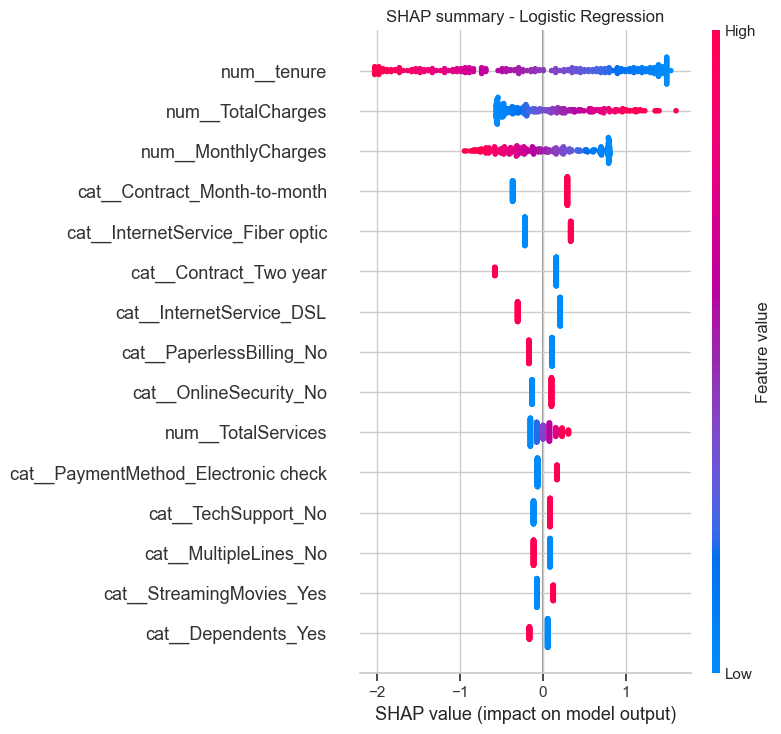

,business_feature,mean_abs_shap,mean_shap,recommended_action
20,tenure,1.0613,0.0157,Prioritize new customers for onboarding and fi...
1,Contract,0.6133,0.0206,Offer a longer-term contract or renewal incent...
4,InternetService,0.5813,0.0154,Investigate service quality and provide proact...
17,TotalCharges,0.4569,-0.0003,Use a targeted customer-care review for this d...
5,MonthlyCharges,0.4382,-0.0132,"Review pricing, discounts, and plan fit for hi..."
8,OnlineSecurity,0.2592,-0.0052,Use a targeted customer-care review for this d...
11,PaymentMethod,0.2467,0.0269,Encourage automatic payment enrollment and res...
14,StreamingMovies,0.2366,-0.0024,Use a targeted customer-care review for this d...
16,TechSupport,0.2258,-0.0012,Offer proactive technical support or a support...
9,PaperlessBilling,0.1869,-0.0191,Use a targeted customer-care review for this d...


In [14]:
# SHAP works for either selected model and is calculated only on held-out test rows.
import shap

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]
X_test_transformed = fitted_preprocessor.transform(X_test)
feature_names = fitted_preprocessor.get_feature_names_out()
sample_size = min(300, X_test_transformed.shape[0])
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(X_test_transformed.shape[0], size=sample_size, replace=False)
X_shap = X_test_transformed[sample_idx]

if best_model_name == "XGBoost":
    explainer = shap.TreeExplainer(fitted_classifier)
    shap_values = explainer.shap_values(X_shap)
else:
    explainer = shap.LinearExplainer(fitted_classifier, X_shap)
    shap_values = explainer.shap_values(X_shap)
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, X_shap, feature_names=feature_names, max_display=15, show=False)
plt.title(f"SHAP summary - {best_model_name}")
plt.tight_layout()
plt.show()

shap_importance = pd.DataFrame({
    "transformed_feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
    "mean_shap": shap_values.mean(axis=0),
})
shap_importance["business_feature"] = (
    shap_importance["transformed_feature"].str.replace(r"^(num|cat)__", "", regex=True)
    .str.replace(r"_[^_]+$", "", regex=True)
)
shap_importance = (shap_importance.groupby("business_feature", as_index=False)
                   .agg(mean_abs_shap=("mean_abs_shap", "sum"), mean_shap=("mean_shap", "sum"))
                   .sort_values("mean_abs_shap", ascending=False))
action_map = {
    "Contract": "Offer a longer-term contract or renewal incentive before the next billing cycle.",
    "tenure": "Prioritize new customers for onboarding and first-90-day support.",
    "MonthlyCharges": "Review pricing, discounts, and plan fit for high-charge customers.",
    "InternetService": "Investigate service quality and provide proactive technical support.",
    "TechSupport": "Offer proactive technical support or a support add-on.",
    "PaymentMethod": "Encourage automatic payment enrollment and resolve payment friction.",
}
actionable_drivers = shap_importance.copy()
actionable_drivers["recommended_action"] = actionable_drivers["business_feature"].map(action_map).fillna(
    "Use a targeted customer-care review for this driver before offering an incentive."
)
display(actionable_drivers.head(10).round({"mean_abs_shap": 4, "mean_shap": 4}))



In [15]:
# Conservative scenario: target model-positive customers with a retention intervention.
# Assumptions are explicit and should be calibrated with a randomized retention test.
CAMPAIGN_REACH = 0.80
SAVE_RATE = 0.20
RETENTION_COST_PER_CONTACT = 100.0
MARGIN_RATE = 0.70

impact_base = X_test.loc[:, ["MonthlyCharges"]].copy()
impact_base["churn_probability"] = test_proba
impact_base["targeted"] = test_proba >= best_threshold
impact_base["annual_contribution_margin"] = impact_base["MonthlyCharges"] * 12 * MARGIN_RATE
predicted_churners = impact_base[impact_base["targeted"]]
contacted = len(predicted_churners) * CAMPAIGN_REACH
retained = contacted * SAVE_RATE
retained_margin = predicted_churners["annual_contribution_margin"].mean() * retained
campaign_cost = contacted * RETENTION_COST_PER_CONTACT
net_savings = retained_margin - campaign_cost
scale_factor = len(df) / len(X_test)
business_impact = pd.DataFrame([{
    "test_set_customers": len(X_test),
    "test_set_targeted": len(predicted_churners),
    "estimated_full_base_targeted": round(len(predicted_churners) * scale_factor),
    "estimated_customers_retained_full_base": round(retained * scale_factor),
    "estimated_annual_margin_preserved": round(retained_margin * scale_factor, 2),
    "estimated_campaign_cost": round(campaign_cost * scale_factor, 2),
    "estimated_net_annual_savings": round(net_savings * scale_factor, 2),
    "assumed_reach": CAMPAIGN_REACH,
    "assumed_save_rate": SAVE_RATE,
    "retention_cost_per_contact": RETENTION_COST_PER_CONTACT,
    "margin_rate": MARGIN_RATE,
}])
display(business_impact)



,test_set_customers,test_set_targeted,estimated_full_base_targeted,estimated_customers_retained_full_base,estimated_annual_margin_preserved,estimated_campaign_cost,estimated_net_annual_savings,assumed_reach,assumed_save_rate,retention_cost_per_contact,margin_rate
0,1057,388,2585,414,263642.9,206825.66,56817.25,0.8,0.2,100.0,0.7


In [16]:
# Reliability checks: all transformations are fit inside training folds, and test labels never tune decisions.
assert "customerID" not in X_train.columns
assert "Churn" not in X_train.columns
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)
assert set(numeric_features).issubset(set(X_train.columns))
assert set(categorical_features).issubset(set(X_train.columns))
assert best_model.named_steps["preprocessor"].transformers_[0][1].named_steps["imputer"].statistics_ is not None
assert 0.0 < best_threshold < 1.0
assert np.isfinite(test_proba).all()
print("Leakage checks passed: split separation, training-fitted preprocessing, validation-only threshold selection, and finite test probabilities.")



Leakage checks passed: split separation, training-fitted preprocessing, validation-only threshold selection, and finite test probabilities.


In [17]:
# The companion app.py is a minimal FastAPI service over the saved pipeline.
# Run outside the notebook with: uvicorn app:app --reload
print("FastAPI deployment source: app.py; health endpoint: GET /health; prediction endpoint: POST /predict")



FastAPI deployment source: app.py; health endpoint: GET /health; prediction endpoint: POST /predict


In [18]:
# Direct comparison on exactly the same untouched held-out test set.
held_out_comparison = []
for name, pipeline in fitted_models.items():
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    held_out_comparison.append(metric_row(y_test, probabilities, 0.5, name))
held_out_comparison = pd.DataFrame(held_out_comparison).set_index("setting")
display(held_out_comparison[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier_score"]].round(4))



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
setting,,,,,,,
Logistic Regression,0.7474,0.5165,0.7794,0.6213,0.8447,0.6577,0.1629
XGBoost,0.7512,0.5227,0.7367,0.6115,0.8310,0.6497,0.1603
